In [14]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import arviz as az
import cmdstanpy
from cmdstanpy import CmdStanModel

cmdstanpy.set_cmdstan_path(os.path.expanduser("~/cmdstan"))

from scipy.special import expit as inv_logit, logit
import networkx as nx

np.random.seed(6300)

In [15]:
policy_metadata = pd.read_csv('./policy-metadata.csv')
policy_metadata.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 645125 entries, 0 to 645124
Data columns (total 27 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   Unnamed: 0      645125 non-null  int64  
 1   hash            645125 non-null  object 
 2   year            645125 non-null  int64  
 3   month           645125 non-null  int64  
 4   timestamp       645125 non-null  int64  
 5   uri             645125 non-null  object 
 6   rank            626688 non-null  float64
 7   flesch          645125 non-null  float64
 8   cl              645125 non-null  float64
 9   smog            645125 non-null  float64
 10  wordcount       645125 non-null  float64
 11  sentencecount   645125 non-null  float64
 12  syllablecount   645125 non-null  float64
 13  count_ccpa      645125 non-null  int64  
 14  count_dnt       645125 non-null  int64  
 15  count_gdpr      645125 non-null  int64  
 16  count_p3p       645125 non-null  int64  
 17  count_priv

# Data
- 2043 website privacy policies  (we use the most recent)
- each observation of interest contains a policyId, wordcount, numobfs (number of obfuscating words), flesch (readability score), rank (tranco site ranking)
- we keep the latest snapshot per site

In [16]:
cols = ['policyid', 'uri', 'year', 'timestamp', 'rank', 'wordcount', 'numobfs', 'flesch']
raw = pd.read_csv('./policy-metadata.csv', usecols=cols)

# Most recent snapshot per site (deterministic tie-break)
latest = (raw.sort_values(['uri', 'timestamp', 'policyid'])
             .groupby('uri').tail(1)
             .set_index('uri'))

# Rank is constant within a site, so take the first non-missing value
site_rank = raw.groupby('uri')['rank'].first()
sites = latest[['year', 'wordcount', 'numobfs', 'flesch']].join(site_rank)


# drop extreme flesch values (outliers)
sites = sites[sites['rank'] > 0]
sites = sites[sites['flesch'] >= 0]
print("analysis sites:", len(sites))
print(sites.describe().round(1))

analysis sites: 2043
         year  wordcount  numobfs  flesch      rank
count  2043.0     2043.0   2043.0  2043.0    2043.0
mean   2019.5     3744.5    310.3    32.8   21462.5
std       3.6     5162.6    311.6     9.5   83491.0
min    2000.0      108.0      2.0     0.7       1.0
25%    2021.0     1099.0     99.0    27.3     654.5
50%    2021.0     2720.0    235.0    32.9    1968.0
75%    2021.0     5022.0    446.0    39.3    7135.5
max    2021.0   132546.0   3935.0    72.3  960506.0


In [33]:
sites['R'] = np.log(sites['rank'])
sites['O'] = np.log(sites['numobfs'])
sites['F'] = sites['flesch']

print(sites[['O', 'F', 'R']].describe().round(2))
print(sites[['O', 'F', 'R']].corr().round(2))

             O        F        R
count  2043.00  2043.00  2043.00
mean      5.24    32.76     7.72
std       1.13     9.49     1.93
min       0.69     0.68     0.00
25%       4.60    27.28     6.48
50%       5.46    32.86     7.58
75%       6.10    39.35     8.87
max       8.28    72.28    13.78
      O     F     R
O  1.00 -0.22 -0.17
F -0.22  1.00  0.10
R -0.17  0.10  1.00


In [35]:
from pathlib import Path
stan_code = r"""
data {
  int<lower=1> N;
  int<lower=2> K;
  matrix[N, K] X;
  vector[N] y;
  real alpha_mean;
  real<lower=0> alpha_sd;
  real<lower=0> beta_sd;
}
parameters {
  vector[K] beta;
  real<lower=0> sigma;
}
model {
  beta[1] ~ normal(alpha_mean, alpha_sd);
  beta[2:K] ~ normal(0, beta_sd);
  sigma ~ exponential(1);
  y ~ normal_id_glm(X, 0, beta, sigma);
}
"""
stan_path = Path("linear_regression.stan")
stan_path.write_text(stan_code)
regression_model = CmdStanModel(stan_file=str(stan_path))

regression_model = CmdStanModel(stan_file=str(stan_path))

def dag(edges, pos=None):
    graph = nx.DiGraph(edges)
    if pos is None:
        pos = nx.spring_layout(graph, seed=6)
    plt.figure(figsize=(4, 3))
    nx.draw_networkx(graph, pos, node_color="white", edgecolors="black",
                     node_size=860, arrowsize=22, font_size=12)
    plt.axis("off")
    return graph

def norm(n, mu=0, sigma=1):
    """Normal draws."""
    return np.random.normal(mu, sigma, size=n)

def corr(x, y):
    """Pearson correlation."""
    return np.corrcoef(x, y)[0, 1]

def regress(y, X, alpha_sd=1, beta_sd=1, alpha_mean=0, **sample_kwargs):
    """Regress y on x with Stan. Takes care of shaping the design matrix."""
    y, X = np.asarray(y, dtype=float), np.asarray(X, dtype=float)
    if X.ndim == 1:
        X = X[:, None]
    design = np.column_stack([np.ones(len(y)), X])
    data = dict(N=len(y), K=design.shape[1], X=design, y=y,
                alpha_mean=alpha_mean, alpha_sd=alpha_sd, beta_sd=beta_sd)
    options = dict(chains=2, parallel_chains=2, iter_warmup=500,
                   iter_sampling=1000, seed=6300, inits=0, step_size=0.01,
                   show_progress=False)
    options.update(sample_kwargs)
    return regression_model.sample(data=data, **options)


11:35:52 - cmdstanpy - INFO - compiling stan file /Users/marobinette/bayesian_statistics/portfolio/3/linear_regression.stan to exe file /Users/marobinette/bayesian_statistics/portfolio/3/linear_regression
11:36:02 - cmdstanpy - INFO - compiled model executable: /Users/marobinette/bayesian_statistics/portfolio/3/linear_regression


# 2 Causal graph and question

$O$ = log number of obfuscating words in the policy, $F$ = Flesch reading ease score (higher is easier to read), $R$ = log Tranco rank (lower means a more popular site).

**Causal question.** If there were a policy that required a site's privacy policy readability (Flesch score) to be a chosen value $f$, how would the site's log Tranco rank change? We compare $E[R \mid do(F = f)]$ across values of $f$.

**Graph.** $O \rightarrow F \rightarrow R$. Intervening on $F$ removes the arrow $O \rightarrow F$, so it does not matter how readability is achieved (fewer obfuscating words or fewer passive sentences). The graph is a pipe, so it implies $R \perp O \mid F$.

**Assumptions (missing arrows).** No direct arrow from $O$ to $R$. No shared cause of $F$ and $R$ other than through $O$.

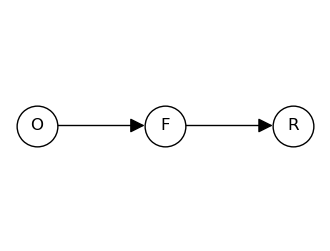

In [37]:
dag([("O", "F"), ("F", "R")], {"O": (-1, 0), "F": (0, 0), "R": (1, 0)});
plt.savefig("figures/dag.png", bbox_inches="tight", dpi=300)

# Fake-data model

For each site $i = 1, \dots, n$ with $n = 2043$:

$$O_i \sim N(5.24,\ 1.13)$$
$$F_i \mid O_i \sim N(32.76 - 4.2\,(O_i - 5.24),\ 8.2)$$
$$R_i \mid F_i \sim N(7.72 - 0.08\,(F_i - 32.76),\ 1.77)$$

The means and SDs of O, F and R match the real data (log obfuscating words, Flesch score, log rank). The true total effect of O on R is $(-4.2)(-0.08) \approx +0.34$. The true effect of the intervention $do(F = f)$ on R is $-0.08$ per Flesch point. The graph implies **R ⟂ O | F**.

# 3 Fake-data model

In [24]:
np.random.seed(6300)
n = 2043
O_sim = norm(n, 5.24, 1.13)
F_sim = norm(n, 32.76 - 4.2 * (O_sim - 5.24), 8.2)
R_sim = norm(n, 7.72 - 0.08 * (F_sim - 32.76), 1.77)

print("corr(O, F):", round(corr(O_sim, F_sim), 3))
print("corr(F, R):", round(corr(F_sim, R_sim), 3))
print("corr(O, R):", round(corr(O_sim, R_sim), 3))
print("means:", round(O_sim.mean(), 2), round(F_sim.mean(), 2), round(R_sim.mean(), 2))
print("SDs:", round(O_sim.std(), 2), round(F_sim.std(), 2), round(R_sim.std(), 2))

corr(O, F): -0.495
corr(F, R): -0.407
corr(O, R): 0.196
means: 5.25 32.54 7.72
SDs: 1.14 9.6 1.95


In [27]:
fit1 = regress(R_sim, O_sim, alpha_mean=7.7, alpha_sd=3, beta_sd=0.5)
fit2 = regress(R_sim, np.column_stack([O_sim, F_sim]), alpha_mean=7.7, alpha_sd=3, beta_sd=0.5)

10:40:19 - cmdstanpy - INFO - CmdStan start processing
10:40:19 - cmdstanpy - INFO - Chain [1] start processing
10:40:19 - cmdstanpy - INFO - Chain [2] start processing
10:40:19 - cmdstanpy - INFO - Chain [1] done processing
10:40:19 - cmdstanpy - INFO - Chain [2] done processing
10:40:19 - cmdstanpy - INFO - CmdStan start processing
10:40:19 - cmdstanpy - INFO - Chain [1] start processing
10:40:19 - cmdstanpy - INFO - Chain [2] start processing
10:40:20 - cmdstanpy - INFO - Chain [2] done processing
10:40:20 - cmdstanpy - INFO - Chain [1] done processing
10:40:20 - cmdstanpy - WARNING - Non-fatal error during sampling:
Exception: normal_id_glm_lpdf: Scale vector is inf, but must be positive finite! (in 'linear_regression.stan', line 19, column 2 to column 39)
Consider re-running with show_console=True if the above output is unclear!


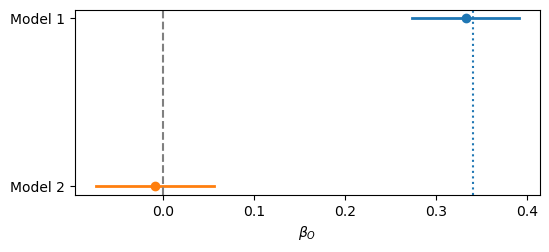

In [38]:
plt.figure(figsize=(6, 2.4))
for row, (label, fit) in enumerate([("Model 1", fit1), ("Model 2", fit2)]):
    b = fit.stan_variable("beta")[:, 1]
    lo, hi = np.quantile(b, [0.05, 0.95])
    plt.plot([lo, hi], [row, row], color=f"C{row}", lw=2)
    plt.plot(b.mean(), row, "o", color=f"C{row}")
plt.yticks([0, 1], ["Model 1", "Model 2"])
plt.gca().invert_yaxis()
plt.axvline(0, color="0.5", linestyle="--")
plt.xlabel(r"$\beta_O$")
plt.axvline(0.34, color="C0", linestyle=":")
plt.savefig("figures/fake_data.png", bbox_inches="tight", dpi=300)

$O$ and $R$ are associated (Model 1). Once we condition on $F$ (Model 2), that association is gone.

In [31]:
fit2.summary()


,Mean,MCSE,StdDev,MAD,5%,50%,95%,ESS_bulk,ESS_tail,ESS_bulk/s,R_hat
lp__,-2200.410000,0.048810,1.376670,1.250350,-2203.010000,-2200.120000,-2198.760000,829.454,1129.980,1040.720,1.001620
beta[1],10.470000,0.012603,0.310189,0.310550,9.963820,10.463600,10.978200,614.489,698.515,771.003,1.001100
beta[2],-0.009397,0.001451,0.038696,0.038811,-0.074179,-0.009332,0.056007,718.277,845.179,901.226,1.001140
beta[3],-0.082950,0.000172,0.004716,0.004574,-0.090792,-0.082908,-0.075179,761.468,810.096,955.418,1.000890
sigma,1.778960,0.000926,0.027641,0.027354,1.733420,1.778710,1.823820,883.304,680.085,1108.290,0.999825
